In [5]:
!pip install -q transformers accelerate datasets
!pip install -q tensorflow scikit-learn pandas numpy matplotlib seaborn

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
import torch

# Check whether GPU is available
if torch.cuda.is_available():

    print("GPU is available!")

    print("GPU Name:", torch.cuda.get_device_name(0))

else:

    print("GPU is not available. Check your runtime settings.")

GPU is available!
GPU Name: Tesla T4


In [8]:
import random

# Set random seed
random.seed(42)

np.random.seed(42)

torch.manual_seed(42)

print("Random seed configured!")

Random seed configured!


In [9]:
import torch
import pandas as pd
import numpy as np
import pyarrow

print("PyTorch:", torch.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyArrow:", pyarrow.__version__)

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Pandas: 3.1.0
NumPy: 2.5.4
PyArrow: 23.0.1
GPU Available: True
GPU: Tesla T4


In [10]:
!wget -q -O amazon_reviews.parquet \
"https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/269765acc4057f11566d9e16106d109409e4c7c8/raw_review_All_Beauty/full-00000-of-00001.parquet"

In [11]:

df = pd.read_parquet("amazon_reviews.parquet")

df.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True
3,1.0,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True
4,5.0,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True


In [12]:
print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Number of rows: 701528
Number of columns: 10


In [13]:
df.shape

(701528, 10)

In [14]:
print("Dataset columns:")

print(df.columns.tolist())

Dataset columns:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 701528 entries, 0 to 701527
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   rating             701528 non-null  float64
 1   title              701528 non-null  str    
 2   text               701528 non-null  str    
 3   images             701528 non-null  object 
 4   asin               701528 non-null  str    
 5   parent_asin        701528 non-null  str    
 6   user_id            701528 non-null  str    
 7   timestamp          701528 non-null  int64  
 8   helpful_vote       701528 non-null  int64  
 9   verified_purchase  701528 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1), str(5)
memory usage: 211.3+ MB


In [16]:
missing_values = df.isnull().sum()

print(missing_values)

rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
dtype: int64


In [17]:
rating_counts = df["rating"].value_counts().sort_index()

print(rating_counts)

rating
1.0    102080
2.0     43034
3.0     56307
4.0     79381
5.0    420726
Name: count, dtype: int64


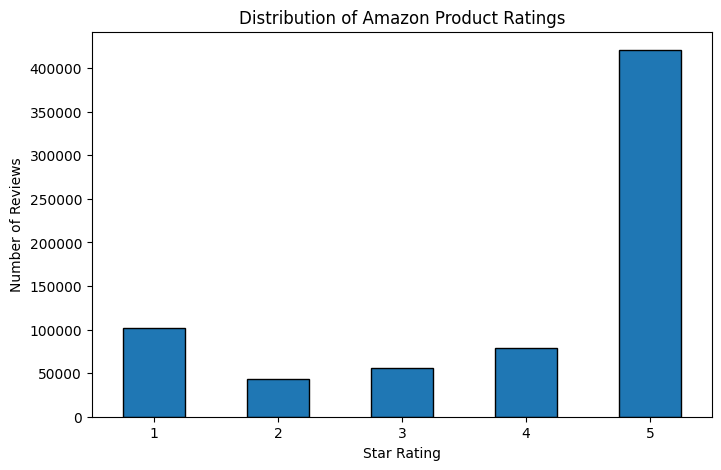

In [18]:
rating_counts = df["rating"].value_counts()

# Arrange ratings in the correct order
rating_counts = rating_counts.reindex(
    [1, 2, 3, 4, 5],
    fill_value=0
)

plt.figure(figsize=(8, 5))

rating_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Distribution of Amazon Product Ratings")

plt.xlabel("Star Rating")

plt.ylabel("Number of Reviews")

plt.xticks(rotation=0)

plt.show()

## Observation from Rating Distribution

The rating distribution shows that the Amazon Reviews
dataset is imbalanced.

Most customers have provided 5-star ratings, while
the number of 2-star and 3-star ratings is relatively low.

This indicates that positive reviews dominate the dataset.

Class imbalance can affect machine learning performance
because the model may become biased towards the majority
class.

Therefore, we will evaluate our models using accuracy,
precision, recall and Macro F1-score.

In [19]:
# Count the number of reviews for each rating
rating_counts = df["rating"].value_counts().sort_index()

# Calculate percentage of each rating
rating_percentage = (
    rating_counts / len(df)
) * 100

# Create a summary table
rating_summary = pd.DataFrame({
    "Total Reviews": rating_counts,
    "Percentage": rating_percentage
})

# Display results
print(rating_summary.round(2))

        Total Reviews  Percentage
rating                           
1.0            102080       14.55
2.0             43034        6.13
3.0             56307        8.03
4.0             79381       11.32
5.0            420726       59.97


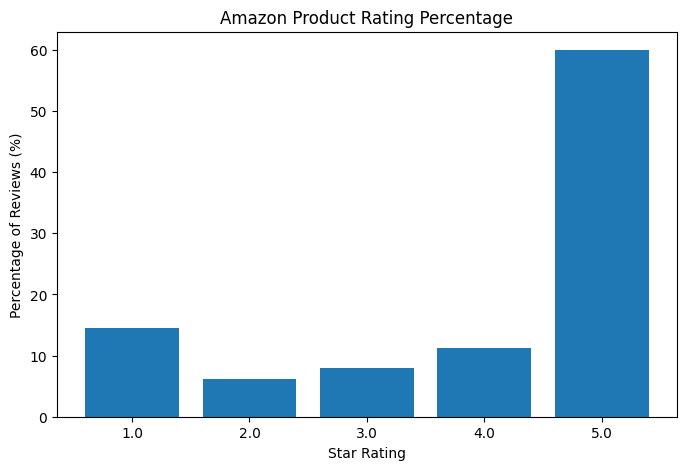

In [20]:
plt.figure(figsize=(8, 5))

plt.bar(
    rating_summary.index.astype(str),
    rating_summary["Percentage"]
)

plt.title("Amazon Product Rating Percentage")

plt.xlabel("Star Rating")

plt.ylabel("Percentage of Reviews (%)")

plt.show()

In [21]:
def convert_sentiment(rating):

    if rating <= 2:
        return 0

    elif rating == 3:
        return 1

    else:
        return 2

In [22]:
df["sentiment"] = df["rating"].apply(convert_sentiment)

df.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,sentiment
0,5.0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,[],B00YQ6X8EO,B00YQ6X8EO,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588687728923,0,True,2
1,4.0,Works great but smells a little weird.,"This product does what I need it to do, I just...",[],B081TJ8YS3,B081TJ8YS3,AGKHLEW2SOWHNMFQIJGBECAF7INQ,1588615855070,1,True,2
2,5.0,Yes!,"Smells good, feels great!",[],B07PNNCSP9,B097R46CSY,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,1589665266052,2,True,2
3,1.0,Synthetic feeling,Felt synthetic,[],B09JS339BZ,B09JS339BZ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1643393630220,0,True,0
4,5.0,A+,Love it,[],B08BZ63GMJ,B08BZ63GMJ,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,1609322563534,0,True,2


In [23]:
label_mapping = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

df["sentiment_name"] = df["sentiment"].map(label_mapping)

display(df[["rating", "sentiment", "sentiment_name"]].head(10))

,rating,sentiment,sentiment_name
0,5.0,2,Positive
1,4.0,2,Positive
2,5.0,2,Positive
3,1.0,0,Negative
4,5.0,2,Positive
5,4.0,2,Positive
6,5.0,2,Positive
7,3.0,1,Neutral
8,5.0,2,Positive
9,5.0,2,Positive


In [24]:
sentiment_counts = df["sentiment_name"].value_counts()

sentiment_percentage = (
    sentiment_counts / len(df)
) * 100

sentiment_summary = pd.DataFrame({
    "Total Reviews": sentiment_counts,
    "Percentage": sentiment_percentage
})

display(sentiment_summary.round(2))

,Total Reviews,Percentage
sentiment_name,,
Positive,500107,71.29
Negative,145114,20.69
Neutral,56307,8.03


## Observation: Class Imbalance

The dataset contains 701,528 customer reviews.

The distribution shows that:
- Positive reviews: 71.29%
- Negative reviews: 20.69%
- Neutral reviews: 8.03%

The Positive class dominates the dataset, while
Neutral reviews represent the minority class.

Therefore, class weighting will be used during
model training to reduce the effect of class imbalance.

In [25]:
df["title"] = df["title"].fillna("")

df["review"] = (
    df["title"] + ". " + df["text"]
)

display(df[["review", "sentiment"]].head())

,review,sentiment
0,Such a lovely scent but not overpowering.. Thi...,2
1,Works great but smells a little weird.. This p...,2
2,"Yes!. Smells good, feels great!",2
3,Synthetic feeling. Felt synthetic,0
4,A+. Love it,2


In [26]:
# Select review text and sentiment labels

data = df[["review", "sentiment"]].copy()

# Check the dataset
print(data.head())

print("\nDataset shape:", data.shape)

                                              review  sentiment
0  Such a lovely scent but not overpowering.. Thi...          2
1  Works great but smells a little weird.. This p...          2
2                    Yes!. Smells good, feels great!          2
3                  Synthetic feeling. Felt synthetic          0
4                                        A+. Love it          2

Dataset shape: (701528, 2)


In [27]:
data = df[["review", "sentiment"]].copy()

print("Total reviews:", len(data))

Total reviews: 701528


In [28]:
from sklearn.model_selection import train_test_split

data, _ = train_test_split(
    data,
    train_size=30000,
    random_state=42,
    stratify=data["sentiment"]
)

print("Selected reviews:", len(data))

Selected reviews: 30000


In [29]:

train_data, temp_data = train_test_split(
    data,
    test_size=0.20,
    random_state=42,
    stratify=data["sentiment"]
)

In [30]:
val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    random_state=42,
    stratify=temp_data["sentiment"]
)

In [39]:
X_train = train_data["review"].values
y_train = train_data["sentiment"].values

X_val = val_data["review"].values
y_val = val_data["sentiment"].values

X_test = test_data["review"].values
y_test = test_data["sentiment"].values

In [40]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.array([0, 1, 2])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(1.6112789526686808), np.int64(1): np.float64(4.153686396677051), np.int64(2): np.float64(0.4675901572271904)}


In [43]:
class_weights = {
    int(key): float(value)
    for key, value in class_weights.items()
}

print(class_weights)

{0: 1.6112789526686808, 1: 4.153686396677051, 2: 0.4675901572271904}


Due to computational and memory limitations,
a stratified sample of 30,000 reviews was selected
from the original Amazon Reviews dataset.

An 80:10:10 split was used for training,
validation and testing.

Stratified sampling was applied to preserve
the original sentiment class distribution.

In [45]:
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

print("TensorFlow Version:", tf.__version__)

print("Available GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [46]:
MAX_WORDS = 30000

MAX_LENGTH = 150

EMBEDDING_DIM = 128

In [47]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_WORDS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

In [48]:
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(256)
)

print("Vocabulary Size:", vectorizer.vocabulary_size())

Vocabulary Size: 25037


In [49]:
sample_review = X_train[0]

print("Original Review:")
print(sample_review)

print("\nNumerical Representation:")
print(vectorizer([sample_review]).numpy())

Original Review:
Pump stopped working. Pump stopped working after a couple weeks

Numerical Representation:
[[587 739 383 587 739 383  65   6 356 284   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0]]


In [62]:
lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [63]:
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 150, 128)       │     3,840,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,947,267 (15.06 MB)

 Trainable params: 3,947,267 (15.06 MB)

 Non-trainable params: 0 (0.00 B)

In [59]:


# Convert review text into string arrays
X_train = np.asarray(X_train, dtype=str)
X_val = np.asarray(X_val, dtype=str)
X_test = np.asarray(X_test, dtype=str)

# Convert sentiment labels into integers
y_train = np.asarray(y_train, dtype=np.int32)
y_val = np.asarray(y_val, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

print("X_train:", X_train.dtype)
print("y_train:", y_train.dtype)

print("X_val:", X_val.dtype)
print("y_val:", y_val.dtype)

X_train: <U6358
y_train: int32
X_val: <U2690
y_val: int32


In [60]:
# Calculate sample weights for training
sample_weights = np.array(
    [class_weights[int(label)] for label in y_train],
    dtype=np.float32
)

# Training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train, sample_weights)
)

train_dataset = (
    train_dataset
    .shuffle(10000)
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_dataset = (
    val_dataset
    .batch(128)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [61]:
import time

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

lstm_history = lstm_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=3,
    callbacks=[early_stop]
)

lstm_training_time = time.time() - start_time

print("LSTM training completed!")

print(
    "Training Time:",
    round(lstm_training_time / 60, 2),
    "minutes"
)

Epoch 1/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.7597 - loss: 0.6885 - val_accuracy: 0.8190 - val_loss: 0.4626
Epoch 2/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.8700 - loss: 0.4265 - val_accuracy: 0.8457 - val_loss: 0.3804
Epoch 3/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.9097 - loss: 0.2942 - val_accuracy: 0.8257 - val_loss: 0.4568
LSTM training completed!
Training Time: 0.36 minutes


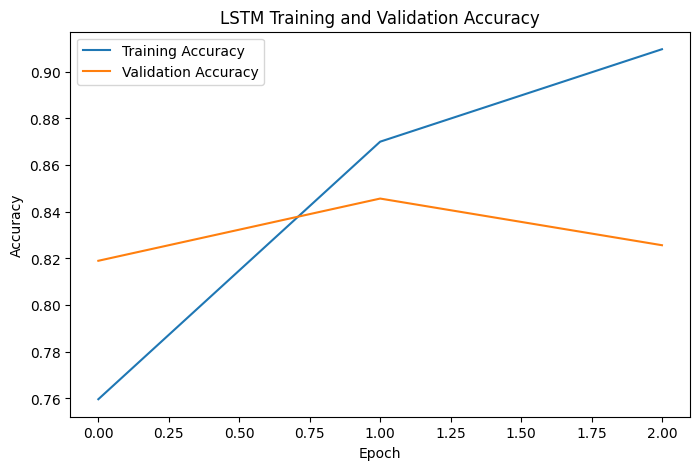

In [64]:
plt.figure(figsize=(8, 5))

plt.plot(
    lstm_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

In [68]:
# Convert test reviews into TensorFlow string tensors
X_test_tensor = tf.constant(
    X_test.tolist(),
    dtype=tf.string
)

# Create test dataset
test_dataset = tf.data.Dataset.from_tensor_slices(
    X_test_tensor
)

# Divide into batches
test_dataset = test_dataset.batch(128)

print("Testing dataset prepared!")

Testing dataset prepared!


In [70]:
# Predict sentiment probabilities
lstm_predictions = lstm_model.predict(
    test_dataset
)

# Convert probabilities into class labels
lstm_pred = np.argmax(
    lstm_predictions,
    axis=1
)

print("Predictions:", lstm_pred[:10])

print("Actual Labels:", y_test[:10])

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
Predictions: [2 2 0 2 2 2 2 2 2 1]
Actual Labels: [2 2 0 2 2 2 2 2 2 1]


In [71]:
from sklearn.metrics import accuracy_score, classification_report

print("LSTM Test Accuracy:")

print(
    accuracy_score(y_test, lstm_pred)
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        lstm_pred,
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

LSTM Test Accuracy:
0.8556666666666667

Classification Report:
              precision    recall  f1-score   support

    Negative       0.85      0.71      0.77       621
     Neutral       0.37      0.59      0.45       241
    Positive       0.94      0.93      0.94      2138

    accuracy                           0.86      3000
   macro avg       0.72      0.74      0.72      3000
weighted avg       0.88      0.86      0.86      3000



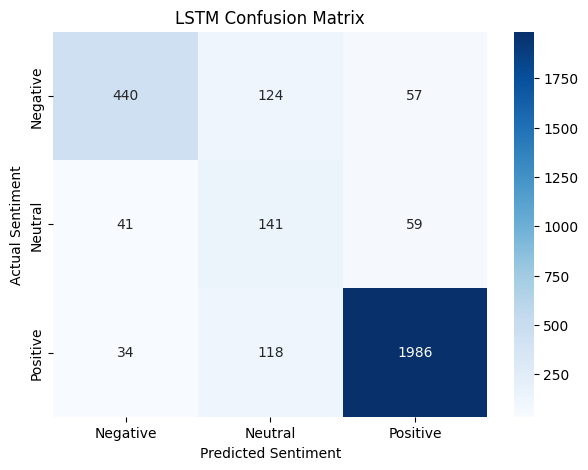

In [72]:
cm = confusion_matrix(
    y_test,
    lstm_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.title("LSTM Confusion Matrix")

plt.show()

In [73]:
lstm_model.save("lstm_sentiment_model.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


## LSTM Model Evaluation

The Bidirectional LSTM model achieved a test accuracy
of 85.57% on 3,000 unseen Amazon product reviews.

Class-wise F1-scores:

- Negative: 0.77
- Neutral: 0.45
- Positive: 0.94

The model performed best on Positive reviews.

However, it showed weaker performance on Neutral
reviews, indicating that distinguishing neutral
sentiment remains challenging.

The overall Macro F1-score was 0.72.

This demonstrates that accuracy alone is not sufficient
for evaluating sentiment classification on an
imbalanced dataset.

In [74]:
!pip install -q transformers

In [75]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
GPU: True


In [76]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training Device:", device)

Training Device: cuda


In [77]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("BERT Tokenizer Loaded!")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BERT Tokenizer Loaded!


In [78]:
sample_text = X_train[0]

tokens = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Original Review:")
print(sample_text)

print("\nToken IDs:")
print(tokens["input_ids"])

print("\nAttention Mask:")
print(tokens["attention_mask"])

Original Review:
Pump stopped working. Pump stopped working after a couple weeks

Token IDs:
tensor([[  101, 10216,  3030,  2551,  1012, 10216,  3030,  2551,  2044,  1037,
          3232,  3134,   102,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,  

In [79]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

model = model.to(device)

print("BERT model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT model loaded successfully!


In [80]:
model.config.id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

model.config.label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

print(model.config.id2label)

{0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [81]:
print(model)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [82]:
MAX_LENGTH = 128

In [83]:
train_encodings = tokenizer(
    X_train.tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print("Training tokenization complete!")
print(train_encodings["input_ids"].shape)

Training tokenization complete!
torch.Size([24000, 128])


In [84]:
val_encodings = tokenizer(
    X_val.tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print(val_encodings["input_ids"].shape)

torch.Size([3000, 128])


In [85]:
test_encodings = tokenizer(
    X_test.tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

print(test_encodings["input_ids"].shape)

torch.Size([3000, 128])


In [86]:
from torch.utils.data import Dataset, DataLoader

In [87]:
class ReviewDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        item = {
            key: value[index]
            for key, value in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels[index]),
            dtype=torch.long
        )

        return item

In [88]:
train_dataset = ReviewDataset(
    train_encodings, y_train
)

val_dataset = ReviewDataset(
    val_encodings, y_val
)

test_dataset = ReviewDataset(
    test_encodings, y_test
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 24000
Validation: 3000
Testing: 3000


In [89]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("All DataLoaders created successfully!")

All DataLoaders created successfully!


In [90]:
batch = next(iter(train_loader))

print("Input IDs:", batch["input_ids"].shape)
print("Attention Mask:", batch["attention_mask"].shape)
print("Labels:", batch["labels"].shape)

Input IDs: torch.Size([16, 128])
Attention Mask: torch.Size([16, 128])
Labels: torch.Size([16])


In [91]:
class_weights_tensor = torch.tensor(
    [
        class_weights[0],
        class_weights[1],
        class_weights[2]
    ],
    dtype=torch.float32
).to(device)

print(class_weights_tensor)

tensor([1.6113, 4.1537, 0.4676], device='cuda:0')


In [92]:
import torch.nn as nn

loss_function = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

print("Loss function created!")

Loss function created!


In [93]:

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5
)

In [94]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-5
)

In [95]:
from transformers import get_linear_schedule_with_warmup

EPOCHS = 2

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(total_steps * 0.1),
    num_training_steps=total_steps
)

In [96]:

start_time = time.time()

bert_train_losses = []
bert_val_losses = []
bert_val_accuracies = []

best_val_loss = float("inf")

for epoch in range(EPOCHS):

    model.train()

    total_train_loss = 0

    for batch in train_loader:

        # Move data to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Get predictions from BERT
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate weighted loss
        loss = loss_function(
            outputs.logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )

        # Update model weights
        optimizer.step()

        scheduler.step()

        total_train_loss += loss.item()

    # Average training loss
    avg_train_loss = total_train_loss / len(train_loader)

    # Validation
    model.eval()

    total_val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for batch in val_loader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Unweighted validation loss
            val_loss = nn.CrossEntropyLoss()(
                outputs.logits,
                labels
            )

            total_val_loss += val_loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=1
            )

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = total_val_loss / len(val_loader)

    val_accuracy = correct / total

    bert_train_losses.append(avg_train_loss)
    bert_val_losses.append(avg_val_loss)
    bert_val_accuracies.append(val_accuracy)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print("Training Loss:", round(avg_train_loss, 4))

    print("Validation Loss:", round(avg_val_loss, 4))

    print("Validation Accuracy:", round(val_accuracy, 4))

    # Save best model
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "best_bert_model.pt"
        )

bert_training_time = time.time() - start_time

# Restore best model
model.load_state_dict(
    torch.load("best_bert_model.pt", map_location=device)
)

print("\nBERT Training Completed!")

print(
    "Training Time:",
    round(bert_training_time / 60, 2),
    "minutes"
)


Epoch 1/2
Training Loss: 0.5962
Validation Loss: 0.2775
Validation Accuracy: 0.8983

Epoch 2/2
Training Loss: 0.3983
Validation Loss: 0.309
Validation Accuracy: 0.8943

BERT Training Completed!
Training Time: 19.16 minutes


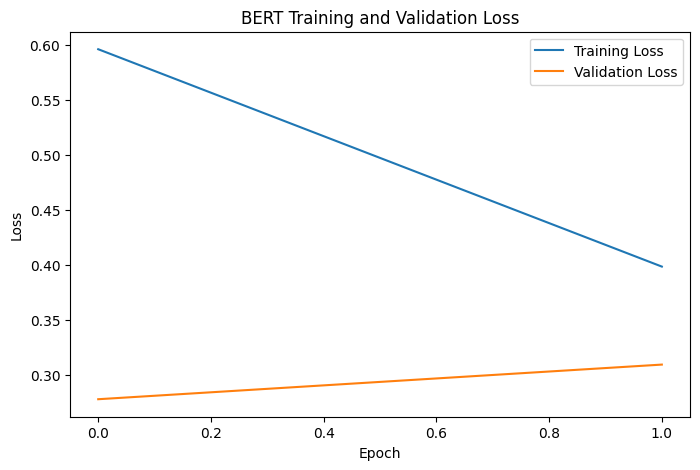

In [97]:
plt.figure(figsize=(8, 5))

plt.plot(
    bert_train_losses,
    label="Training Loss"
)

plt.plot(
    bert_val_losses,
    label="Validation Loss"
)

plt.title("BERT Training and Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.show()

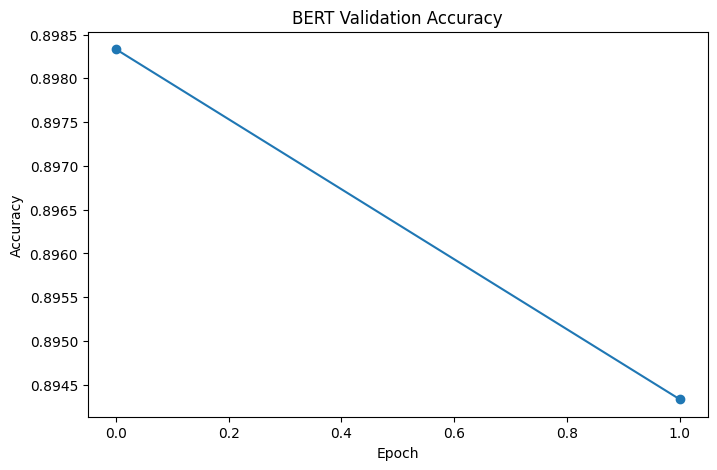

In [98]:
plt.figure(figsize=(8, 5))

plt.plot(
    bert_val_accuracies,
    marker="o"
)

plt.title("BERT Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.show()

In [99]:
model.eval()

bert_predictions = []
bert_actual = []

with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)

        attention_mask = batch["attention_mask"].to(device)

        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        bert_predictions.extend(
            predictions.cpu().numpy()
        )

        bert_actual.extend(
            labels.cpu().numpy()
        )

print("BERT predictions:", bert_predictions[:10])
print("Actual labels:", bert_actual[:10])

BERT predictions: [np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(1)]
Actual labels: [np.int64(2), np.int64(2), np.int64(0), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(2), np.int64(1)]


In [100]:
from sklearn.metrics import accuracy_score

bert_accuracy = accuracy_score(
    bert_actual,
    bert_predictions
)

print("BERT Test Accuracy:", bert_accuracy)

print(
    "BERT Accuracy Percentage:",
    round(bert_accuracy * 100, 2),
    "%"
)

BERT Test Accuracy: 0.907
BERT Accuracy Percentage: 90.7 %


In [101]:
from sklearn.metrics import classification_report

print(
    classification_report(
        bert_actual,
        bert_predictions,
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.85      0.90      0.87       621
     Neutral       0.53      0.53      0.53       241
    Positive       0.97      0.95      0.96      2138

    accuracy                           0.91      3000
   macro avg       0.78      0.79      0.79      3000
weighted avg       0.91      0.91      0.91      3000



In [102]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],

    "LSTM": [
        accuracy_score(y_test, lstm_pred),
        precision_score(y_test, lstm_pred, average="macro"),
        recall_score(y_test, lstm_pred, average="macro"),
        f1_score(y_test, lstm_pred, average="macro")
    ],

    "BERT": [
        accuracy_score(bert_actual, bert_predictions),
        precision_score(bert_actual, bert_predictions, average="macro"),
        recall_score(bert_actual, bert_predictions, average="macro"),
        f1_score(bert_actual, bert_predictions, average="macro")
    ]

})

display(comparison.round(4))

,Metric,LSTM,BERT
0,Accuracy,0.8557,0.9070
1,Macro Precision,0.7224,0.7820
2,Macro Recall,0.7408,0.7918
3,Macro F1,0.7211,0.7867


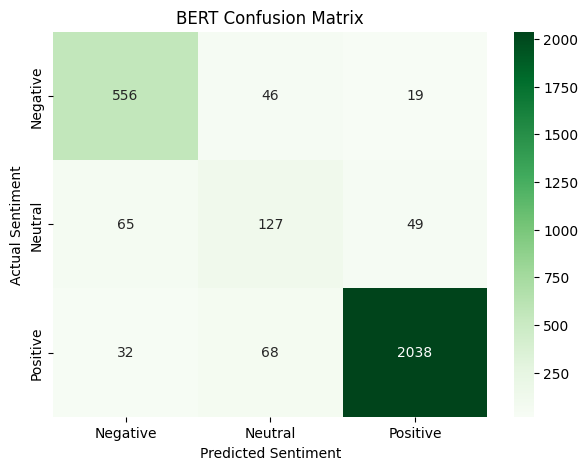

In [103]:
cm = confusion_matrix(
    bert_actual,
    bert_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("BERT Confusion Matrix")

plt.xlabel("Predicted Sentiment")

plt.ylabel("Actual Sentiment")

plt.show()

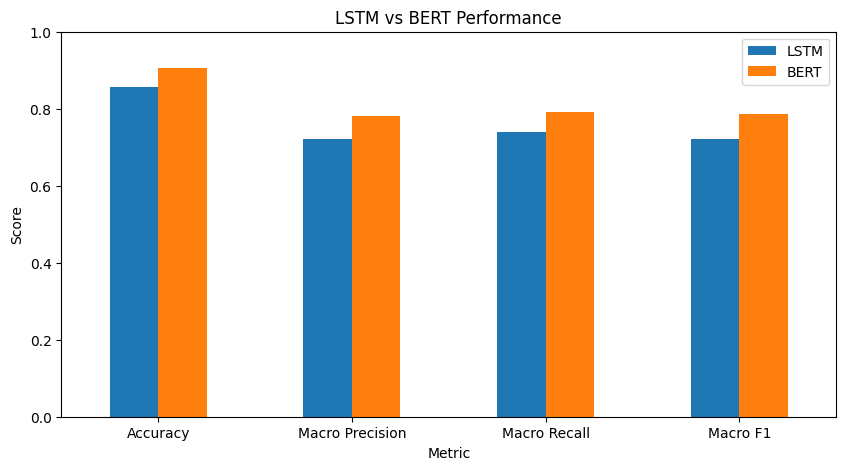

In [104]:
comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("LSTM vs BERT Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

## Experimental Results and Model Comparison

The LSTM and BERT models were trained using the same
Amazon Reviews dataset and evaluated on the same
test dataset containing 3,000 reviews.

### LSTM Results
- Accuracy: 85.57%
- Macro Precision: 72.24%
- Macro Recall: 74.08%
- Macro F1-score: 72.11%

### BERT Results
- Accuracy: 90.70%
- Macro Precision: 78.20%
- Macro Recall: 79.18%
- Macro F1-score: 78.67%

### Observation

BERT achieved better performance than the LSTM model
across all four evaluation metrics.

BERT improved the Macro F1-score by 6.56 percentage
points compared with LSTM.

However, BERT required considerably more training
time and computational resources.

Therefore, BERT demonstrated better classification
performance, while LSTM offered a computationally
lighter alternative.

## BERT Confusion Matrix Analysis

The confusion matrix shows that the BERT model correctly
classified 2,721 out of 3,000 test reviews.

The model performed particularly well on Positive
reviews, correctly classifying 2,038 reviews.

It also achieved good performance on Negative reviews,
with 556 correct predictions.

However, Neutral sentiment was more difficult to
classify, with only 127 out of 241 reviews correctly
identified.

The overall test accuracy was 90.70%.

This suggests that BERT performs well on the Amazon
review sentiment classification task, although
distinguishing Neutral sentiment remains a challenge.

In [105]:
lstm_time = lstm_training_time / 60
bert_time = bert_training_time / 60

print("LSTM Training Time:", round(lstm_time, 2), "minutes")
print("BERT Training Time:", round(bert_time, 2), "minutes")

print(
    "BERT took approximately",
    round(bert_time / lstm_time, 2),
    "times longer to train."
)

LSTM Training Time: 0.36 minutes
BERT Training Time: 19.16 minutes
BERT took approximately 52.89 times longer to train.


In [106]:
lstm_parameters = lstm_model.count_params()

bert_parameters = sum(
    p.numel() for p in model.parameters()
)

print("LSTM Parameters:", f"{lstm_parameters:,}")
print("BERT Parameters:", f"{bert_parameters:,}")

LSTM Parameters: 3,947,267
BERT Parameters: 109,484,547


In [107]:
efficiency_comparison = pd.DataFrame({

    "Metric": [
        "Test Accuracy",
        "Macro F1",
        "Training Time (minutes)",
        "Parameters"
    ],

    "LSTM": [
        0.8557,
        0.7211,
        round(lstm_time, 2),
        lstm_parameters
    ],

    "BERT": [
        0.9070,
        0.7867,
        round(bert_time, 2),
        bert_parameters
    ]

})

display(efficiency_comparison)

,Metric,LSTM,BERT
0,Test Accuracy,8.557000e-01,9.070000e-01
1,Macro F1,7.211000e-01,7.867000e-01
2,Training Time (minutes),3.600000e-01,1.916000e+01
3,Parameters,3.947267e+06,1.094845e+08


## 9. Transfer Learning Efficiency

Transfer learning is a machine learning technique in
which knowledge from a pre-trained model is reused
for a new task.

In this project, we used the pre-trained BERT Base
Uncased model from HuggingFace.

BERT was fine-tuned on 24,000 Amazon product reviews
to perform three-class sentiment classification.

The experimental results were:

LSTM:
- Accuracy: 85.57%
- Macro F1: 0.7211
- Training time: 0.36 minutes

BERT:
- Accuracy: 90.70%
- Macro F1: 0.7867
- Training time: 19.16 minutes

BERT achieved better classification performance
because it started with pre-trained language
representations.

However, BERT required considerably more training
time and computational resources than LSTM.

Therefore, transfer learning provided better
classification performance in our experiment,
but involved a higher computational cost.

In [110]:
# Save trained BERT model
model.save_pretrained("bert_sentiment_model")

# Save tokenizer
tokenizer.save_pretrained("bert_sentiment_model")

print("BERT model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model and tokenizer saved successfully!


In [112]:
print(os.listdir("bert_sentiment_model"))

['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


In [113]:
total_size = 0

for file in os.listdir("bert_sentiment_model"):

    path = os.path.join("bert_sentiment_model", file)

    if os.path.isfile(path):
        total_size += os.path.getsize(path)

bert_size = total_size / (1024 * 1024)

print("BERT Model Size:", round(bert_size, 2), "MB")

BERT Model Size: 418.35 MB


In [114]:
print("LSTM Model Size:", round(lstm_size, 2), "MB")

print("BERT Model Size:", round(bert_size, 2), "MB")




LSTM Model Size: 15.51 MB
BERT Model Size: 418.35 MB


In [115]:

review = X_test[0]

# Convert review into TensorFlow input
lstm_input = tf.constant([review], dtype=tf.string)

# Warm-up
for i in range(5):
    lstm_model(lstm_input, training=False)

# Measure prediction time
start = time.perf_counter()

for i in range(100):
    lstm_model(lstm_input, training=False)

lstm_latency = (time.perf_counter() - start) / 100

print("LSTM Latency:", round(lstm_latency * 1000, 2), "ms")

LSTM Latency: 59.08 ms


In [116]:

model.eval()

inputs = tokenizer(
    review,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=128
).to(device)

# Warm-up
with torch.no_grad():
    for i in range(5):
        model(**inputs)

if torch.cuda.is_available():
    torch.cuda.synchronize()

start = time.perf_counter()

with torch.no_grad():
    for i in range(100):
        model(**inputs)

if torch.cuda.is_available():
    torch.cuda.synchronize()

bert_latency = (time.perf_counter() - start) / 100

print("BERT Latency:", round(bert_latency * 1000, 2), "ms")

BERT Latency: 24.08 ms


In [117]:
final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Training Time (minutes)",
        "Model Size (MB)"
    ],

    "LSTM": [
        0.8557,
        0.7224,
        0.7408,
        0.7211,
        0.36,
        15.51
    ],

    "BERT": [
        0.9070,
        0.7820,
        0.7918,
        0.7867,
        19.16,
        418.35
    ]

})

display(final_results)

,Metric,LSTM,BERT
0,Accuracy,0.8557,0.9070
1,Macro Precision,0.7224,0.7820
2,Macro Recall,0.7408,0.7918
3,Macro F1,0.7211,0.7867
4,Training Time (minutes),0.3600,19.1600
5,Model Size (MB),15.5100,418.3500


# 11. Conclusion

In this project, we developed a sentiment analysis
system using Amazon product reviews.

The objective was to classify customer reviews into
three categories: Positive, Neutral and Negative.

We used the Amazon Reviews 2023 dataset, containing
701,528 original reviews. A stratified sample of
30,000 reviews was selected for the experiment.

Two deep learning models were implemented:

1. Bidirectional LSTM
2. Pre-trained BERT using HuggingFace Transformers

## Experimental Results

The LSTM model achieved:

- Accuracy: 85.57%
- Macro Precision: 72.24%
- Macro Recall: 74.08%
- Macro F1-score: 72.11%

The BERT model achieved:

- Accuracy: 90.70%
- Macro Precision: 78.20%
- Macro Recall: 79.18%
- Macro F1-score: 78.67%

## Model Comparison

BERT performed better than LSTM across all reported
evaluation metrics.

BERT improved test accuracy by 5.13 percentage points
and Macro F1-score by 6.56 percentage points.

However, BERT required more training time and storage.

The LSTM model was smaller and faster to train,
while BERT provided better classification performance.

## Transfer Learning Efficiency

BERT used pre-trained language representations
and was fine-tuned for sentiment classification.

This demonstrated the usefulness of transfer learning
for understanding contextual information in customer
reviews.

## Deployment Considerations

The deployment of BERT requires consideration of
model size, inference latency, GPU memory, hosting
cost, scalability and data privacy.

Optimization techniques such as quantization,
DistilBERT and ONNX Runtime can help reduce
computational requirements.

## Final Conclusion

Based on our experimental results, BERT is the
better-performing model for this sentiment analysis
task.

LSTM is a suitable alternative when computational
resources, storage and training speed are important.

The project demonstrates the advantages and
trade-offs of transfer learning in real-world
sentiment analysis applications.

## Limitations

Sentiment labels were generated from star ratings.
Therefore, they may not perfectly represent the
actual emotional meaning of every review.

Only 30,000 reviews were used for the experiment
because of computational limitations.

In [118]:

import shutil

os.makedirs("Final_Sentiment_Project", exist_ok=True)

# Save LSTM model
lstm_model.save(
    "Final_Sentiment_Project/lstm_model.keras"
)

# Save BERT model
model.save_pretrained(
    "Final_Sentiment_Project/bert_model"
)

tokenizer.save_pretrained(
    "Final_Sentiment_Project/bert_model"
)

# Save comparison results
final_results.to_csv(
    "Final_Sentiment_Project/model_comparison.csv",
    index=False
)

print("Project files saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Project files saved successfully!


In [119]:
import os
import shutil
import pandas as pd
import numpy as np

# Create main project folder
folder = "Sentiment_Analysis_Project"

os.makedirs(folder, exist_ok=True)

# Save LSTM model
lstm_model.save(
    f"{folder}/lstm_sentiment_model.keras"
)

# Save BERT model
model.save_pretrained(
    f"{folder}/bert_model"
)

# Save BERT tokenizer
tokenizer.save_pretrained(
    f"{folder}/bert_model"
)

print("Both models saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Both models saved successfully!


In [120]:
# Prepare training data
train_export = pd.DataFrame({
    "review": X_train,
    "sentiment": y_train,
    "split": "train"
})

# Prepare validation data
val_export = pd.DataFrame({
    "review": X_val,
    "sentiment": y_val,
    "split": "validation"
})

# Prepare testing data
test_export = pd.DataFrame({
    "review": X_test,
    "sentiment": y_test,
    "split": "test"
})

# Combine all datasets
processed_data = pd.concat(
    [train_export, val_export, test_export],
    ignore_index=True
)

processed_data["sentiment_name"] = processed_data[
    "sentiment"
].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

processed_data.to_csv(
    f"{folder}/processed_amazon_reviews.csv",
    index=False
)

print("30,000 processed reviews saved!")

30,000 processed reviews saved!


In [121]:
final_results = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Training Time (minutes)",
        "Model Size (MB)"
    ],

    "LSTM": [
        0.8557,
        0.7224,
        0.7408,
        0.7211,
        0.36,
        15.51
    ],

    "BERT": [
        0.9070,
        0.7820,
        0.7918,
        0.7867,
        19.16,
        418.35
    ]

})

final_results.to_csv(
    f"{folder}/model_comparison.csv",
    index=False
)

display(final_results)

,Metric,LSTM,BERT
0,Accuracy,0.8557,0.9070
1,Macro Precision,0.7224,0.7820
2,Macro Recall,0.7408,0.7918
3,Macro F1,0.7211,0.7867
4,Training Time (minutes),0.3600,19.1600
5,Model Size (MB),15.5100,418.3500


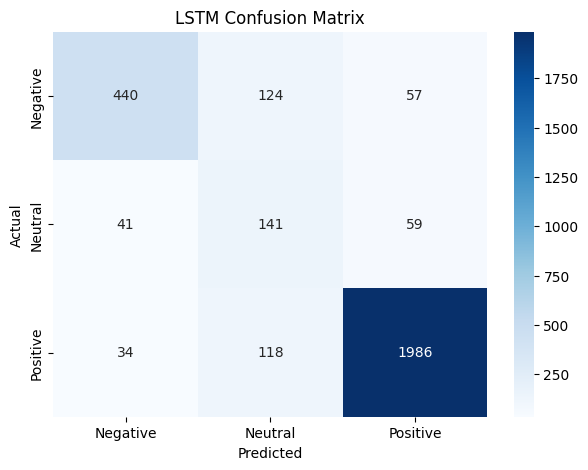

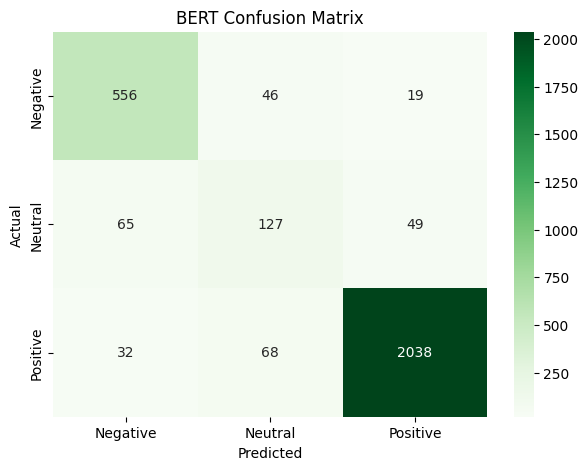

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# LSTM confusion matrix
lstm_cm = confusion_matrix(y_test, lstm_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lstm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    f"{folder}/lstm_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()


# BERT confusion matrix
bert_cm = confusion_matrix(y_test, bert_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    bert_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title("BERT Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    f"{folder}/bert_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

In [123]:
if os.path.exists("amazon_reviews.parquet"):

    shutil.copy(
        "amazon_reviews.parquet",
        f"{folder}/amazon_reviews.parquet"
    )

    print("Original Amazon dataset copied!")

else:

    print("Original Parquet file not found. Skipping it.")

Original Amazon dataset copied!


In [125]:
readme = """
AMAZON PRODUCT REVIEW SENTIMENT ANALYSIS
========================================

DATASET
-------
Amazon Reviews 2023 - All Beauty
Original Reviews: 701,528
Experiment Samples: 30,000

DATA SPLIT
----------
Training: 24,000
Validation: 3,000
Testing: 3,000

SENTIMENT LABELS
----------------
0 = Negative
1 = Neutral
2 = Positive

MODELS
------
1. Bidirectional LSTM
2. BERT Base Uncased (HuggingFace)

EXPERIMENTAL RESULTS
--------------------
LSTM Accuracy: 85.57%
BERT Accuracy: 90.70%

LSTM Macro F1: 0.7211
BERT Macro F1: 0.7867

TRAINING TIME
-------------
LSTM: 0.36 minutes
BERT: 19.16 minutes

MODEL SIZE
----------
LSTM: 15.51 MB
BERT: 418.35 MB

PROJECT OBJECTIVE
-----------------
Three-class sentiment classification of Amazon
product reviews using LSTM and fine-tuned BERT.

IMPORTANT
---------
Sentiment labels are generated from star ratings.
These labels may not perfectly represent the actual
emotional meaning of every review.
"""

with open(
    f"{folder}/README.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(readme)

print("README created!")

README created!


In [126]:
import shutil

zip_path = shutil.make_archive(
    "Sentiment_Analysis_Project",
    "zip",
    root_dir=folder
)

print("ZIP created:", zip_path)

print(
    "ZIP Size:",
    round(os.path.getsize(zip_path) / (1024 * 1024), 2),
    "MB"
)

ZIP created: /content/Sentiment_Analysis_Project.zip
ZIP Size: 508.92 MB


In [127]:
from google.colab import files

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>